# 01 - Data preparation and exploratory analysis

Data: `val.csv` of the Booking.com dataset (about 200,000 reviews).

| # | Step |
|---|---|
| 1 | Environment |
| 2 | Loading and data quality |
| 3 | Why the guest score is not a sentiment label |
| 4 | Filtering and cleaning |
| 5 | Exploratory analysis |
| 6 | Saving the working set |

This notebook does not create sentiment labels; notebook 02 produces them from the text.

## 1. Environment

In [1]:
# The notebooks run from notebooks/, so the project root is added to the path.
import sys, os
sys.path.insert(0, os.path.abspath(".."))

import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src import set_seed
from src.config import CFG, PATHS, SENTIMENT_COLORS, INK, APPROACHES, apply_plot_style
from src import data_loading as dl
from src import preprocessing as pp
from src import evaluation as ev
from src import descriptives as ds
from src import pipeline

set_seed()
PATHS.ensure()
apply_plot_style()
pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 170)

print(f"pandas {pd.__version__} | numpy {np.__version__} | seed {CFG.random_seed}")
print(f"Data file: data/raw/booking/{CFG.local_csv_name}")

pandas 3.0.6 | numpy 2.5.3 | seed 42
Data file: data/raw/booking/val.csv


## 2. Loading and data quality

`val.csv` is the validation part of the official Booking.com split. In this project it is the whole working dataset, not the validation set of the models, which is why it is called `booking_val_split` in the code.

In [2]:
df_raw = dl.load_booking()
print(f"Loaded: {len(df_raw):,} rows, {df_raw.shape[1]} columns")
df_raw.head(3)

17:15:48 | INFO    | src.data_loading | Loading from cache: booking_local_val__v3.parquet


Loaded: 203,787 rows, 21 columns


,review_id,text,score,score_scale_max,dataset,review_title,review_positive,review_negative,guest_type,guest_country,...,month,accommodation_id,accommodation_type,accommodation_score,accommodation_country,accommodation_star_rating,location_is_beach,location_is_ski,location_is_city_center,review_helpful_votes
0,booking_val_split_0,"Hope is relatively close to where I live, so this might just become a ""hop on the bike and cruise there for a weeke....",9.0,10.0,booking_val_split,"Hope is relatively close to where I live, so this might just become a ""hop on the bike and cruise there for a weeke","This motel is in the Center of Hope. You can get groceries, restaurants, pubs on food in just short distance, a movi...",,Group,Jof,...,8,-225497943,Motel,7.7,Canada,3.0,0,0,0,0
1,booking_val_split_1,Close to the station and within walking distance of the centre,8.0,10.0,booking_val_split,,Close to the station and within walking distance of the centre,,Solo traveller,Mejok,...,7,2110216461,Hotel,7.7,Netherlands,3.0,0,0,1,0
2,booking_val_split_2,"Excellent service. Excellent customer service, great location and the view, good breakfast spread, easy access to ci...",8.0,10.0,booking_val_split,Excellent service,"Excellent customer service, great location and the view, good breakfast spread, easy access to city centre, clean fa...",Kept on waking up in the middle of the night to a noisy boiler or something.,Family with children,Mejok,...,3,-1626991710,Hotel,7.9,United Kingdom,3.0,0,0,0,0


In [3]:
print(df_raw.dtypes.to_string())
print("\n=== Missing values ===")
miss = ds.missing_report(df_raw)
print(miss.to_string() if len(miss) else "No missing values.")
n_dup = df_raw["text"].duplicated().sum()
print(f"\n=== Duplicates (by text) === {n_dup:,} rows ({n_dup/len(df_raw):.2%})")
print("\n=== Guest score ===")
print(df_raw["score"].describe().round(2).to_string())

review_id                        str
text                          string
score                        float64
score_scale_max              float64
dataset                          str
review_title                     str
review_positive                  str
review_negative                  str
guest_type                       str
guest_country                    str
room_nights                    int64
month                          int64
accommodation_id               int64
accommodation_type               str
accommodation_score          float64
accommodation_country            str
accommodation_star_rating    float64
location_is_beach              int64
location_is_ski                int64
location_is_city_center        int64
review_helpful_votes           int64

=== Missing values ===
               missing   share
guest_country      228  0.0011

=== Duplicates (by text) === 409 rows (0.20%)

=== Guest score ===
count    203787.00
mean          8.87
std           1.15
min         

## 3. Why the guest score is not a sentiment label

The guest score rates the whole stay, while the tone of the text can differ. Booking collects praise and complaints in separate fields, so if the complaint field is often filled in high-score reviews, the "positive" class of a score cut contains mixed texts.

,n,share_with_complaint,share_with_praise
score_int,,,
3,32,0.875,1.000
4,129,0.915,0.953
5,1246,0.932,0.966
6,4742,0.935,0.982
7,20503,0.885,0.984
8,45729,0.756,0.987
9,50968,0.614,0.993
10,80438,0.397,0.994


17:15:51 | INFO    | src.evaluation | Table saved: 01_score_vs_written_fields.csv
17:15:51 | INFO    | src.evaluation | Figure saved: 01_score_vs_written_fields.png


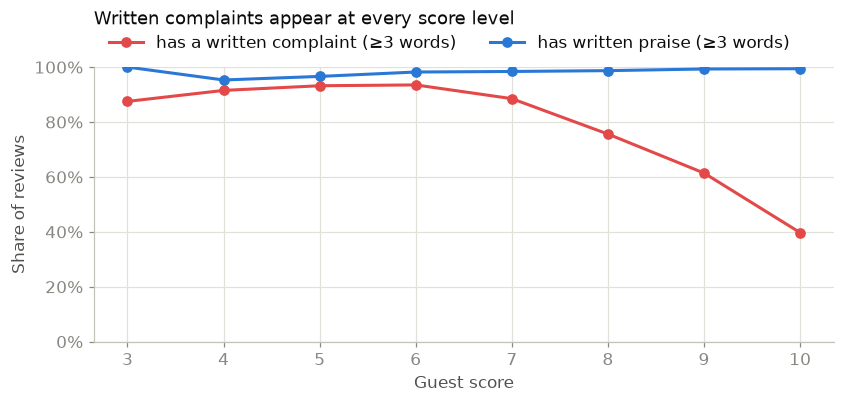

Among reviews scored 9–10, 48.1% contain a written complaint.


In [4]:
has_complaint = df_raw["review_negative"].fillna("").str.split().str.len() >= 3
has_praise = df_raw["review_positive"].fillna("").str.split().str.len() >= 3

score_vs_fields = (df_raw.assign(score_int=df_raw["score"].round().astype(int),
                                 has_complaint=has_complaint, has_praise=has_praise)
                         .groupby("score_int")
                         .agg(n=("score", "size"),
                              share_with_complaint=("has_complaint", "mean"),
                              share_with_praise=("has_praise", "mean"))
                         .round(3))
display(score_vs_fields)
ev.save_table(score_vs_fields, "01_score_vs_written_fields")

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.plot(score_vs_fields.index, score_vs_fields["share_with_complaint"], "o-",
        color=SENTIMENT_COLORS["negative"], lw=2, label="has a written complaint (≥3 words)")
ax.plot(score_vs_fields.index, score_vs_fields["share_with_praise"], "o-",
        color=SENTIMENT_COLORS["positive"], lw=2, label="has written praise (≥3 words)")
ax.set(xlabel="Guest score", ylabel="Share of reviews", ylim=(0, 1))
ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax.set_title("Written complaints appear at every score level", loc="left", pad=28)
ax.legend(loc="lower left", bbox_to_anchor=(0, 1.0), ncol=2)
plt.tight_layout(); ev.save_figure("01_score_vs_written_fields"); plt.show()

high = score_vs_fields.loc[score_vs_fields.index >= 9]
print(f"Among reviews scored 9–10, {np.average(high['share_with_complaint'], weights=high['n']):.1%} "
      "contain a written complaint.")

In [5]:
# Examples: 10 points with a real complaint.
examples = df_raw[(df_raw["score"] >= 10) & (df_raw["review_negative"].str.split().str.len() >= 12)]
for _, r in examples.sample(min(5, len(examples)), random_state=CFG.random_seed).iterrows():
    print(f"[score {r['score']:.0f}]  NEGATIVE FIELD: {r['review_negative'][:220]}\n")

[score 10]  NEGATIVE FIELD: A couple of broken tiles on the balcony. But nothing major at all. Jacuzzi would be better situated on the back of the property rather than looking out onto the strip.

[score 10]  NEGATIVE FIELD: We liked it a lot all and owners kept it super clean , probably would do shower enclosure rather than curtain in the bathroom but that is being too picky

[score 10]  NEGATIVE FIELD: Paying extra (in cash) for parking could have been mentioned up front upon confirmation of booking.

[score 10]  NEGATIVE FIELD: In front of our room were several office furniture boxes which made entering and leaving our room uncomfortable.

[score 10]  NEGATIVE FIELD: The Wifi wasnt great and the TV impossible.  We didnt want to go far as it was our last night in Costa Rica and an early start was due.   The airport transfer is not free so we took an Uber.  USD 16 for the hotel transfe



## 4. Filtering and cleaning

Two cleaning paths: `text_bert` (minimal, for BERT) and `text_clean` (full, for TF-IDF).

In [6]:
df, filter_log = pp.build_dataset(df_raw)
display(filter_log)
ev.save_table(filter_log.set_index("step"), "01_filtering_log")
print(f"Final size: {len(df):,} rows")

17:15:56 | INFO    | src.preprocessing | --- Filtering log ---
                                 step   rows  change
                                start 203787       0
      short texts (<10 chars) removed 203662    -125
very long texts (>5000 chars) removed 203662       0
                   duplicates removed 203340    -322
            non-English texts removed 203328     -12
17:16:00 | INFO    | src.preprocessing | Classical cleaning on 203328 rows (lemmatisation is the slow part)...


,step,rows,change
0,start,203787,0
1,short texts (<10 chars) removed,203662,-125
2,very long texts (>5000 chars) removed,203662,0
3,duplicates removed,203340,-322
4,non-English texts removed,203328,-12


17:16:26 | INFO    | src.evaluation | Table saved: 01_filtering_log.csv


Final size: 203,328 rows


In [7]:
ex = df.iloc[0]
print("ORIGINAL:\n ", ex["text"][:280])
print("\nFor BERT (minimal):\n ", ex["text_bert"][:280])
print("\nFor TF-IDF (full):\n ", ex["text_clean"][:280])

ORIGINAL:
  Hope is relatively close to where I live, so this might just become a "hop on the bike and cruise there for a weeke. This motel is in the Center of Hope. You can get groceries, restaurants, pubs on food in just short distance, a movie theatre just around the corner and as well a 

For BERT (minimal):
  Hope is relatively close to where I live, so this might just become a "hop on the bike and cruise there for a weeke. This motel is in the Center of Hope. You can get groceries, restaurants, pubs on food in just short distance, a movie theatre just around the corner and as well a 

For TF-IDF (full):
  hope relatively close live might become hop bike cruise weeke motel center hope get grocery restaurant pub food short distance movie theatre around corner well small nice park next building look like could use bit love outside room extraordinarily clean especially motel absolutel


In [8]:
# Truncation estimate for several max_length values (the complaint part is at the end).
trunc = pd.DataFrame({L: pp.truncation_report(df, max_length=L).loc["truncated"] for L in [128, 192, 256, 384]}).T
trunc.index.name = "max_length"
display(trunc)
ev.save_table(trunc, "01_truncation_by_max_length")
print(f"Current setting: CFG.max_length = {CFG.max_length}")

,share,count
max_length,,
128,0.1067,21694.0
192,0.0360,7322.0
256,0.0140,2846.0
384,0.0031,640.0


17:16:32 | INFO    | src.evaluation | Table saved: 01_truncation_by_max_length.csv


Current setting: CFG.max_length = 256


## 5. Exploratory analysis

17:16:32 | INFO    | src.evaluation | Figure saved: 01_eda_overview.png


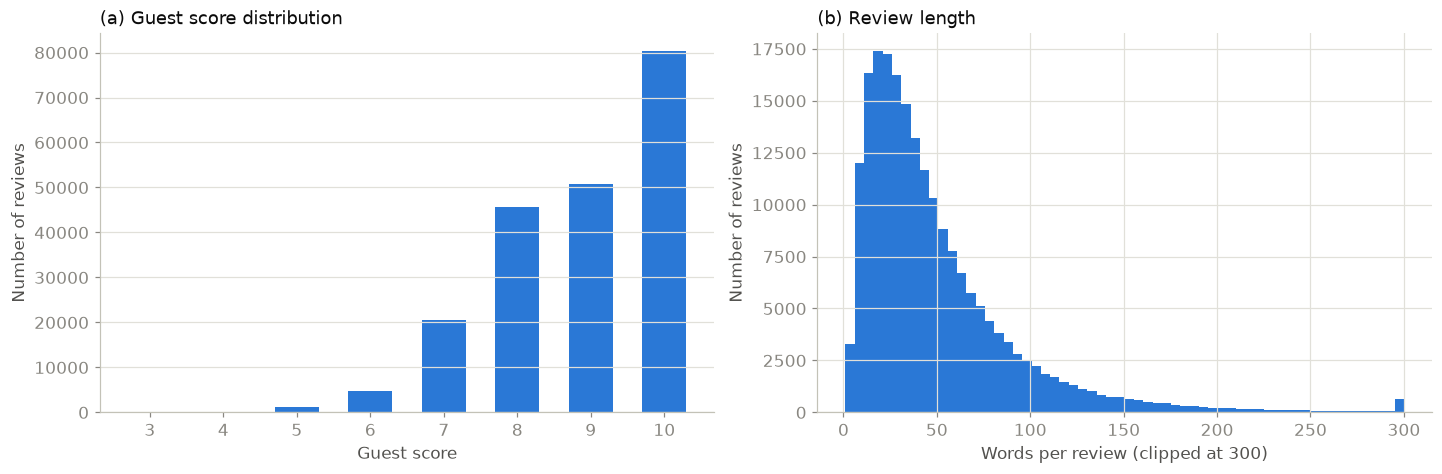

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), constrained_layout=True)

vc = df["score"].round().value_counts().sort_index()
axes[0].bar(vc.index, vc.values, width=0.6, color="#2a78d6")
axes[0].set(xlabel="Guest score", ylabel="Number of reviews")
axes[0].set_title("(a) Guest score distribution", loc="left")
axes[0].grid(axis="x", visible=False)

axes[1].hist(df["n_words"].clip(upper=300), bins=60, color="#2a78d6")
axes[1].set(xlabel="Words per review (clipped at 300)", ylabel="Number of reviews")
axes[1].set_title("(b) Review length", loc="left")
ev.save_figure("01_eda_overview"); plt.show()

In [10]:
df = ds.prepare_star_rating(df)
overview = ds.dataset_overview(df, label_col=None)
display(overview); ev.save_table(overview, "01_dataset_overview")
profile = ds.numeric_profile(df)
display(profile); ev.save_table(profile, "01_numeric_profile")

17:16:33 | INFO    | src.descriptives | Star rating: 64997 rows (32.0%) had 0 -> 'n/a'.


,Value
Metric,
Number of reviews,"203,328"
Unique properties,"5,000"
Number of countries,120
Accommodation types,24
Mean guest score,8.87
Median guest score,9.00
Guest score std,1.16
Mean review length (words),49.2
Median review length (words),37


17:16:33 | INFO    | src.evaluation | Table saved: 01_dataset_overview.csv


,count,mean,std,min,5%,25%,50%,75%,95%,max
score,203328.0,8.87,1.16,3.0,7.0,8.0,9.0,10.0,10.0,10.0
n_words,203328.0,49.21,43.67,1.0,9.0,21.0,37.0,63.0,130.0,733.0
n_chars,203328.0,278.88,237.37,10.0,55.0,126.0,214.0,355.0,716.0,3922.0
room_nights,203328.0,2.59,2.39,1.0,1.0,1.0,2.0,3.0,7.0,112.0
accommodation_score,203328.0,8.38,0.74,4.2,7.0,8.0,8.4,8.9,9.5,10.0
review_helpful_votes,203328.0,0.14,0.78,0.0,0.0,0.0,0.0,0.0,1.0,87.0


17:16:33 | INFO    | src.evaluation | Table saved: 01_numeric_profile.csv


WindowsPath('C:/Users/seszt/Documents/BCE/7_felev/Szakdolgozat/THESIS/CODE/results/tables/01_numeric_profile.csv')

17:16:33 | INFO    | src.evaluation | Figure saved: 01_counts_accommodation_country.png


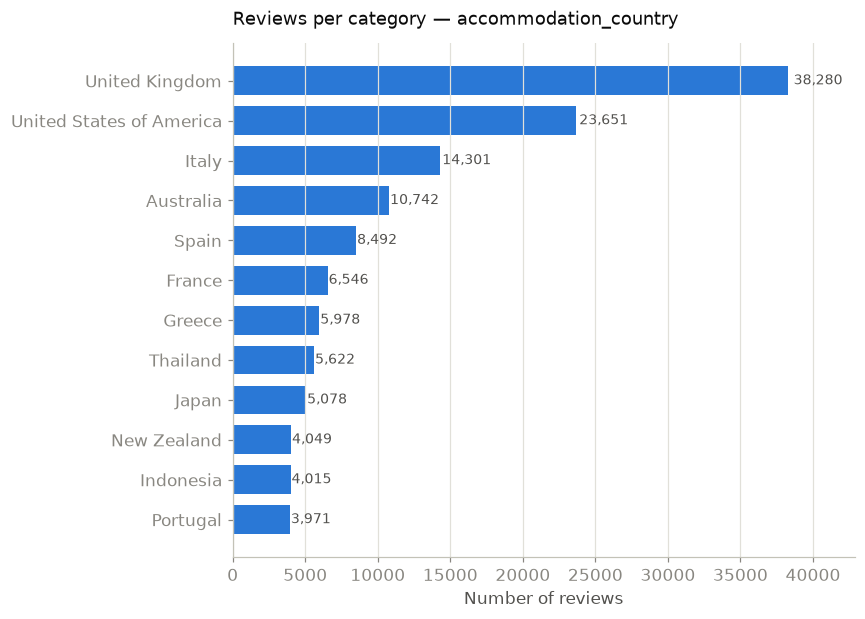

17:16:34 | INFO    | src.evaluation | Figure saved: 01_counts_accommodation_type.png


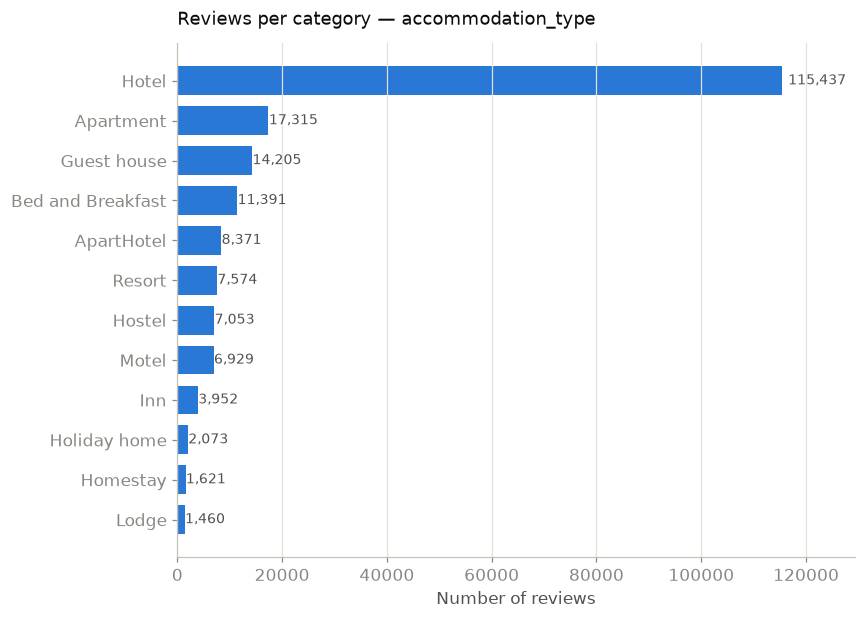

17:16:34 | INFO    | src.evaluation | Figure saved: 01_counts_guest_type.png


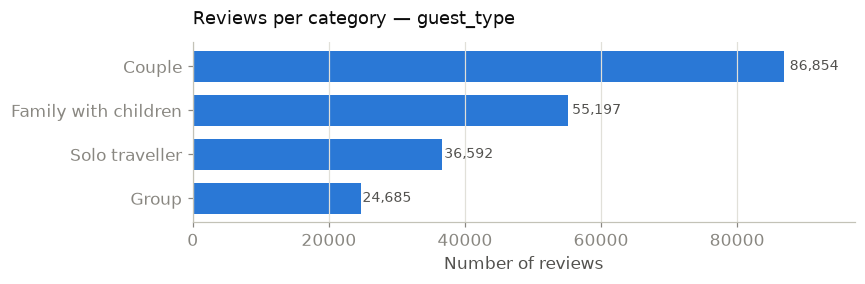

guest_country examples (pseudonymised): ['Jof', 'Mejok', 'Zuc', 'Sajeb', 'Dawal', 'Gobuf']


In [11]:
for col in ["accommodation_country", "accommodation_type", "guest_type"]:
    if col in df.columns:
        ds.plot_top_categories(df, col, title=f"Reviews per category — {col}", save_as=f"01_counts_{col}")
        plt.show()

# guest_country is pseudonymised, so it is left out of the analysis.
if "guest_country" in df.columns:
    print("guest_country examples (pseudonymised):", df["guest_country"].dropna().unique()[:6].tolist())

## 6. Saving the working set

BERT labelling of 200k reviews takes 15–30 minutes per model on a GPU, so development used a random working set of `CFG.labelling_sample_size` reviews (`None` = full data in the final run). All three labelling approaches run on the same set, which keeps them comparable.

In [12]:
dl.write_frame(df, pipeline.PREPARED)
n = CFG.labelling_sample_size
working = df.sample(n, random_state=CFG.random_seed) if n and n < len(df) else df
path = dl.write_frame(working.reset_index(drop=True), pipeline.WORKING_SET)
CFG.to_json(PATHS.processed / "config_snapshot.json")
print(f"Prepared: {len(df):,} rows | working set: {len(working):,} rows -> {path.name}")
print("Next: 02_bert_labelling.ipynb (GPU)")

Prepared: 203,328 rows | working set: 203,328 rows -> booking_working_set.parquet
Next: 02_bert_labelling.ipynb (GPU)
